In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [18]:
df = pd.read_csv("survey.csv", sep=';')
df.head()

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,27.08.2014 11:29,37,Female,United States,IL,NaN,No,Yes,Often,45809,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,27.08.2014 11:29,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,27.08.2014 11:29,32,Male,Canada,NaN,NaN,No,No,Rarely,45809,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,27.08.2014 11:29,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,27.08.2014 11:30,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


In [19]:
# drop last and first column
df.drop(df.columns[0], axis=1, inplace=True)
df.drop(df.columns[-1], axis=1, inplace=True)

# show column names with missing values along with their types
for col in df.columns:
    if df[col].isna().sum() > 0:
        print(col, df[col].dtype, df[col].isna().sum())
print('\n')

# list unique values in each column to determine stupid values
for col in df.columns:
    print(col, df[col].unique())
    print('\n')

state str 515
self_employed str 18
work_interfere str 264


Age [         37          44          32          31          33          35
          39          42          23          29          36          27
          46          41          34          30          40          38
          50          24          18          28          26          22
          19          25          45          21         -29          43
          56          60          54         329          55 99999999999
          48          20          57          58          47          62
          51          65          49       -1726           5          53
          61           8          11          -1          72]


Gender <StringArray>
[                                       'Female',
                                             'M',
                                          'Male',
                                          'male',
                                        'female',
                 

In [20]:
# apply missing value handling strategy for each column with missing values

# drop rows with age below 18 and above 100
df = df[(df['Age'] >= 18) & (df['Age'] <= 100)]

# sort gender column by assigning 3 unique values: female, male, other
drop_values = ['Nah', 'A little about you', 'p']
df = df[~df['Gender'].isin(drop_values)].copy()
df['Gender'] = df['Gender'].str.lower().str.strip()

male_terms = [
    'm', 'male', 'male-ish', 'maile', 'something kinda male?', 'cis male', 
    'mal', 'male (cis)', 'make', 'guy (-ish) ^_^', 'male leaning androgynous', 
    'man', 'msle', 'mail', 'malr', 'cis man', 
    'ostensibly male unsure what that really means'
]

female_terms = [
    'female', 'trans-female', 'cis female', 'f', 'woman', 'femake', 
    'cis-female/femme', 'trans woman', 'female (trans)', 'female (cis)', 'femail'
]

other_terms = [
    'queer/she/they', 'non-binary', 'all', 'enby', 'fluid', 'genderqueer', 
    'androgyne', 'agender', 'neuter', 'queer'
]

category_mapping = {}
for term in male_terms: category_mapping[term] = 'Male'
for term in female_terms: category_mapping[term] = 'Female'
for term in other_terms: category_mapping[term] = 'Other'
df['Gender'] = df['Gender'].map(category_mapping)

# substitute missing values in self_employed column with mode
mode_value = df['self_employed'].mode()[0]
df['self_employed'] = df['self_employed'].fillna(mode_value)

# substitute missing values in work_interfere column with new value 'no_illness'
df['work_interfere'] = df['work_interfere'].fillna('no_illness')

# substitute missing values in state column with 'not_US'
df['state'] = df['state'].fillna('not_US')

# due to silly excel properties, like exchanging interval 6-25 with date june 2025, adjustments need to be made in no_employees column
df['no_employees'] = df['no_employees'].replace({'45809': '6-25', '46143': '1-5'})

In [21]:
# check if there are still missing values
print(df.isna().sum(), '\n')
for col in df.columns:
    print(col, df[col].unique())
    print('\n')

Age                          0
Gender                       0
Country                      0
state                        0
self_employed                0
family_history               0
treatment                    0
work_interfere               0
no_employees                 0
remote_work                  0
tech_company                 0
benefits                     0
care_options                 0
wellness_program             0
seek_help                    0
anonymity                    0
leave                        0
mental_health_consequence    0
phys_health_consequence      0
coworkers                    0
supervisor                   0
mental_health_interview      0
phys_health_interview        0
mental_vs_physical           0
obs_consequence              0
dtype: int64 

Age [37 44 32 31 33 35 39 42 23 29 36 27 46 41 34 30 40 38 50 24 18 28 26 22
 19 25 45 21 43 56 60 54 55 48 20 57 58 47 62 51 65 49 53 61 72]


Gender <StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype:

In [22]:
# EDA for Age column

sns.boxplot(data=df, x='Age', ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribution of age')

Text(0.5, 1.0, 'Distribution of age')

C:\Users\natalcia\AppData\Local\Temp\ipykernel_16264\3947231483.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Gender', ax=axes[0, 1], palette='Set2')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_16264\3947231483.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='no_employees', order=size_order, ax=axes[1, 0], palette='viridis')
C:\Users\natalcia\AppData\Local\Temp\ipykernel_16264\3947231483.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='work_interfere', order=interfere_order, ax=axes[

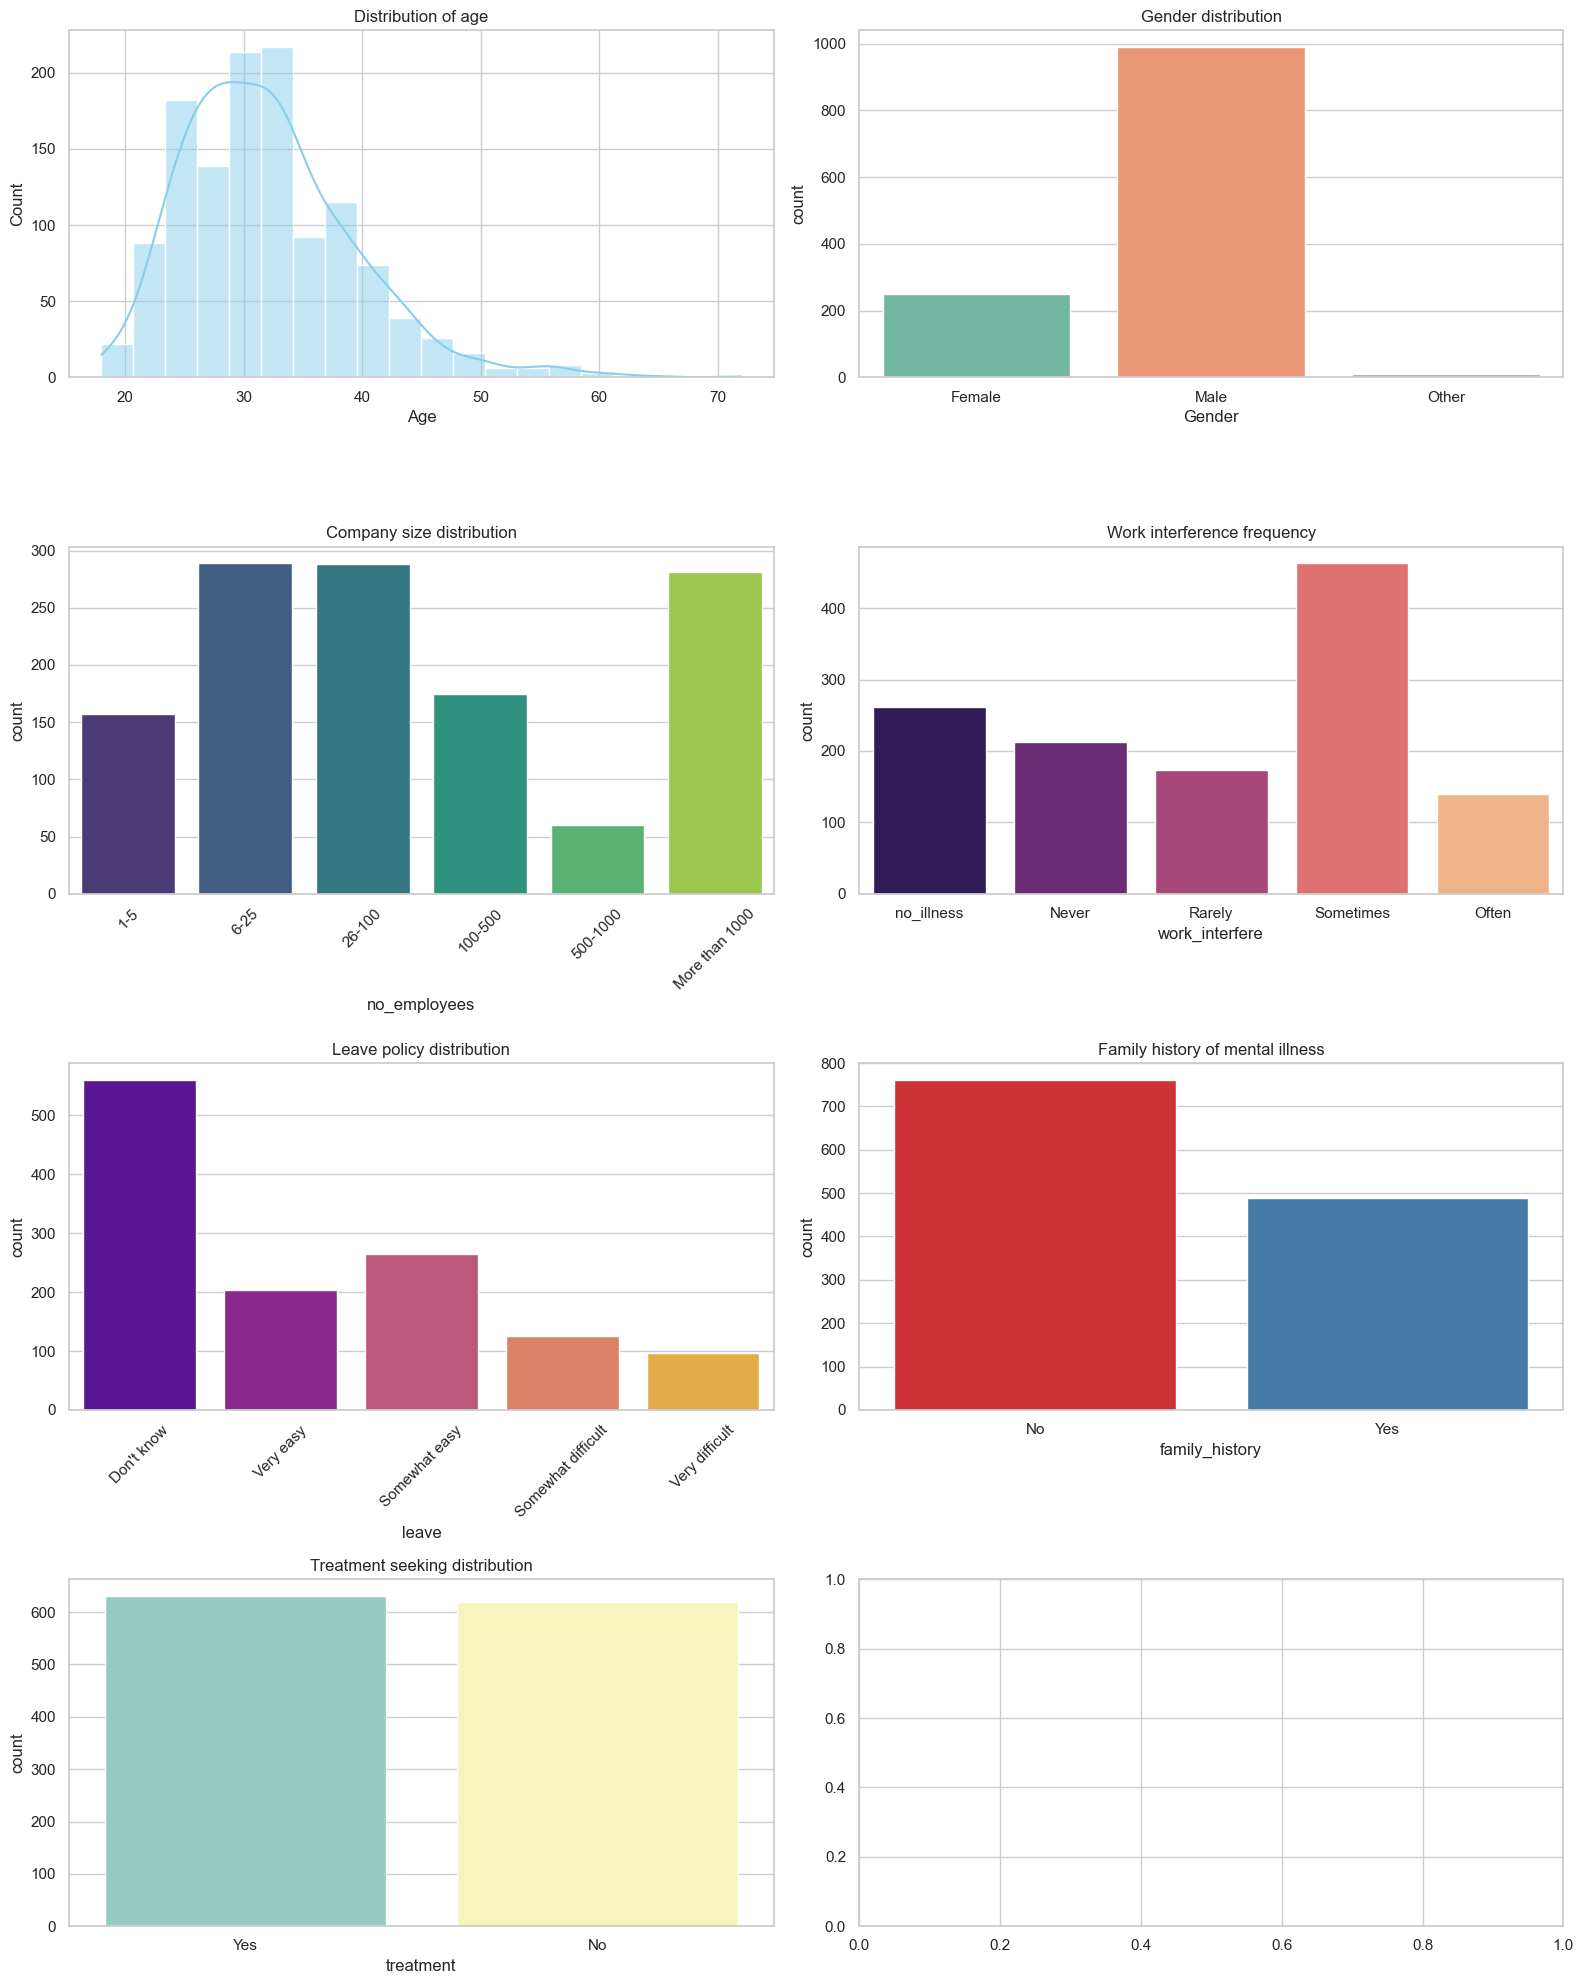

In [23]:
# EDA - exploratory data analysis

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(4, 2, figsize=(16, 20))

sns.histplot(data=df, x='Age', ax=axes[0, 0], color='skyblue', bins=20, kde=True)
axes[0, 0].set_title('Distribution of age')

sns.countplot(data=df, x='Gender', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Gender distribution')

size_order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
sns.countplot(data=df, x='no_employees', order=size_order, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Company size distribution')
axes[1, 0].tick_params(axis='x', rotation=45)

interfere_order = ['no_illness', 'Never', 'Rarely', 'Sometimes', 'Often']
sns.countplot(data=df, x='work_interfere', order=interfere_order, ax=axes[1, 1], palette='magma')
axes[1, 1].set_title('Work interference frequency')

leave_order = ['Don\'t know', 'Very easy', 'Somewhat easy', 'Somewhat difficult', 'Very difficult']
sns.countplot(data=df, x='leave', order=leave_order, ax=axes[2, 0], palette='plasma')
axes[2, 0].set_title('Leave policy distribution')
axes[2, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=df, x='family_history', ax=axes[2, 1], palette='Set1')
axes[2, 1].set_title('Family history of mental illness')

sns.countplot(data=df, x='treatment', ax=axes[3, 0], palette='Set3')
axes[3, 0].set_title('Treatment seeking distribution')

plt.tight_layout()
plt.show()

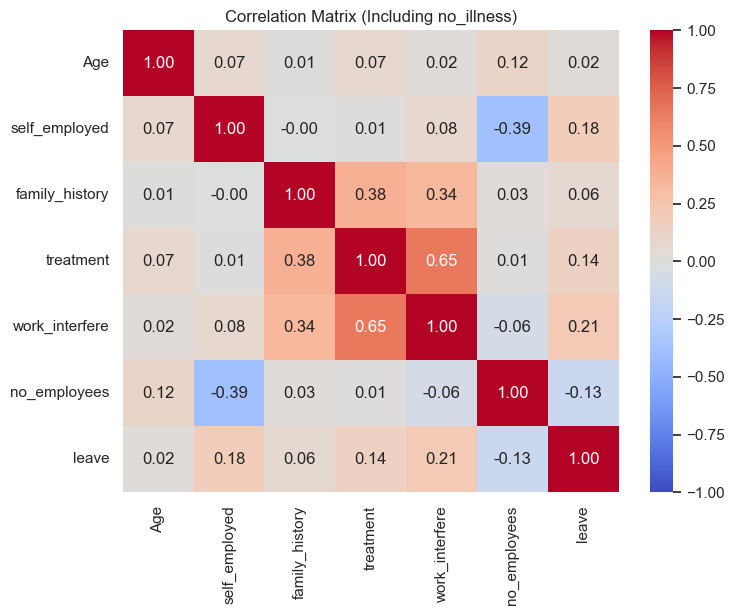

In [24]:
# CORRELATIONS BETWEEN ATTRIBUTES
df_encoded = df.copy()

# binary encoding
binary_cols = ['treatment', 'family_history', 'self_employed']
for col in binary_cols:
    if col in df_encoded.columns:
        df_encoded[col] = df_encoded[col].map({'Yes': 1, 'No': 0})

# ordinal encoding for work_interfere (0 = no illness, 4 = often)
if 'work_interfere' in df_encoded.columns:
    interfere_map = {'no_illness': 0, 'Never': 1, 'Rarely': 2, 'Sometimes': 3, 'Often': 4}
    df_encoded['work_interfere'] = df_encoded['work_interfere'].map(interfere_map)

# ordinal encoding for no_employees (0 = 1-5, 5 = More than 1000)
if 'no_employees' in df_encoded.columns:
    employees_map = {'1-5': 0, '6-25': 1, '26-100': 2, '100-500': 3, '500-1000': 4, 'More than 1000': 5}
    df_encoded['no_employees'] = df_encoded['no_employees'].map(employees_map)

# ordinal encoding for leave (0 = Don't know, 4 = Very difficult)
if 'leave' in df_encoded.columns:
    leave_map = {'Don\'t know': 0, 'Very easy': 1, 'Somewhat easy': 2, 'Somewhat difficult': 3, 'Very difficult': 4}
    df_encoded['leave'] = df_encoded['leave'].map(leave_map)

# heatmap
plt.figure(figsize=(8, 6))
numeric_df = df_encoded.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix (Including no_illness)')
plt.show()